# Geodesic vs. Tangent-Regression Baseline — Video Reconstruction

Fully-sampled (denoising) comparison on the video dataset, with **$\ell > r$** so the
two-stage baseline can estimate a local rank-$r$ subspace at each time point.

**Baseline (the reviewer's suggestion).** Estimate a local subspace $\widehat U_i$ per time
point, anchor at the **global SVD subspace** $U_0$, lift each estimate to the tangent space via
the Grassmann log $\xi_i=\operatorname{Log}_{U_0}(\widehat U_i)$, fit an **affine line in the
(linear) tangent space** over time, map back with the exp map, and project the noisy frames onto
the smoothed subspaces.

**What we report.** Reconstruction error (**NRMSE** $=\|\widehat X - X\|_F/\|X\|_F$) and
**PSNR** against the clean frames. No subspace error — there is no ground-truth subspace for real
video. Because we add the noise ourselves, the clean target $X$ is known.

**Fairness.** Both models have $\approx 2nr$ degrees of freedom (geodesic: $[H,Z]\in\mathcal V^{n\times 2r}$;
tangent fit: intercept + slope, two $n\times r$ tangent matrices). Both see the **same** noisy data
each trial and are scored with the **same** metric code.

## Imports

In [1]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from skimage.metrics import peak_signal_noise_ratio as psnr
import matplotlib.pyplot as plt

np.random.seed(0)

## Load and preprocess the video

In [2]:
# Pick a dataset (uncomment one). Mouse used by default, as in the original notebook.
with np.load('img_utils/orig_mouse_data.npz') as data:
    data = data['arr_0']
# with np.load('img_utils/plane_data_new.npz') as data:
#     data = data['arr_0']

x, y = data.shape[0], data.shape[1]
frames = data.shape[2]
print('frame size:', x, y, '| num frames:', frames)

frame size: 70 100 | num frames: 90


In [3]:
# vectorize each frame (column-major to match the original), scale to [0,1], mean-center
vec_data = np.reshape(data, (-1, frames), order='F') / 255.0
vec_data_norm = vec_data - np.mean(vec_data, axis=0)
d = x * y

In [4]:
RANK = 3
ELL  = 5          # samples per time point; ELL > RANK so the local rank-r SVD is well defined
assert ELL > RANK, "Tangent baseline needs ELL > RANK (local rank-r subspace per time point)."

Xs = []
st, en = 0, ELL
for i in range(frames // ELL):
    Xs.append(vec_data_norm[:, st:en]); st += ELL; en += ELL
T = len(Xs)
X_clean = np.concatenate(Xs, axis=1)        # clean (mean-centered) ground-truth data
print(f'T = {T} | ELL = {ELL} | RANK = {RANK} | ell > r: {ELL > RANK}')

T = 18 | ELL = 5 | RANK = 3 | ell > r: True


## Metric helpers (identical for every method)

Computed on the concatenated data matrix so all methods are scored the same way. The per-frame
PSNR uses the same `psnr(normalize_np(.), normalize_np(.))` convention as the original notebook's
figures.

In [5]:
def nrmse(Xhat, Xtrue):
    "Normalized RMSE over the whole sequence: ||Xhat - Xtrue||_F / ||Xtrue||_F."
    return np.linalg.norm(Xhat - Xtrue) / np.linalg.norm(Xtrue)

def mean_psnr(Xhat, Xtrue):
    "Per-frame PSNR averaged over frames; returns (mean, per_frame_array)."
    vals = np.array([psnr(normalize_np(Xhat[:, j]), normalize_np(Xtrue[:, j]))
                     for j in range(Xtrue.shape[1])])
    return float(vals.mean()), vals

def noop_cb(itr, geo, data):
    return False   # keep iterating; we score after .fit returns

## Grassmann log / exp and the tangent-regression baseline

`grassmann_log` matches Eq. (16) of the paper with $H_1 = U_0$: the singular values of
$(I-U_0U_0^\top)U_1(U_0^\top U_1)^{-1}$ are $\tan$ of the principal angles, so $\Theta=\arctan(S)$.
We avoid forming the $d\times d$ identity.

In [6]:
def topr_subspace(M, r):
    "Orthonormal basis for the dominant r-subspace of M (top-r left singular vectors)."
    U, _, _ = la.svd(M, full_matrices=False)
    return U[:, :r]

def grassmann_log(U0, U1):
    "Tangent vector xi at U0 pointing to span(U1); xi is d x r with U0^T xi = 0."
    M = (U1 - U0 @ (U0.T @ U1)) @ np.linalg.pinv(U0.T @ U1)
    W, s, Vt = la.svd(M, full_matrices=False)     # M = W diag(s) Vt
    theta = np.arctan(s)                          # principal angles
    return W @ np.diag(theta) @ Vt

def grassmann_exp(U0, xi):
    "Geodesic point reached from U0 along tangent xi; returns an orthonormal d x r basis."
    W, sig, Vt = la.svd(xi, full_matrices=False)  # xi = W diag(sig) Vt
    V = Vt.T
    B = U0 @ V @ np.diag(np.cos(sig)) + W @ np.diag(np.sin(sig))  # already orthonormal
    Q, _ = np.linalg.qr(B)                        # re-orthonormalize for numerical safety
    return Q

In [7]:
def tangent_regression_baseline(Ys_list, ts, rank):
    "Two-stage log-Euclidean baseline anchored at the global SVD subspace."
    Y_all = np.concatenate(Ys_list, axis=1)
    U0 = topr_subspace(Y_all, rank)                            # (2) global SVD reference

    # (1)+(3) local subspaces lifted into the common tangent space at U0
    xis = [grassmann_log(U0, topr_subspace(Yi, rank)) for Yi in Ys_list]
    Xi_mat = np.stack([xi.ravel() for xi in xis], axis=0)      # (T, d*r)

    # (4) affine least-squares fit  xi_i ~ a + t_i * b  (closed form, per coordinate)
    D = np.vstack([np.ones_like(ts), ts]).T                    # (T, 2)
    coef, *_ = np.linalg.lstsq(D, Xi_mat, rcond=None)          # (2, d*r)
    Xi_fit = D @ coef                                          # (T, d*r)

    # (5) exp back, then project the (fully observed) noisy data onto the smoothed subspace
    dd, r = U0.shape
    recon = []
    for i, Yi in enumerate(Ys_list):
        Ui = grassmann_exp(U0, Xi_fit[i].reshape(dd, r))
        recon.append(Ui @ (Ui.T @ Yi))
    return np.concatenate(recon, axis=1)

## Experiment configuration

In [34]:
SIGMA   = 0.25                                              # noise std (fully-sampled denoising)
NTRIALS = 1                                                # noise realizations to average
NITERS  = 3                                               # geodesic MM iterations
LAMBDA  = 1.0                                             # subspace-regularizer weight (lambda=1 fully sampled)
TS = np.linspace(0.0, 1.0, T + 30, endpoint=False)[15:-15] # ~[0.3,0.7], as in the original notebook
assert len(TS) == T

# Fully sampled => identity sensing operator (A = I): all-ones masks, forward/transpose are identity.
masks_full = [np.ones_like(Xi) for Xi in Xs]
forward   = lambda Xi, m: Xi * m
transpose = lambda Yi, m: Yi * m

## Comparison loop

Same noisy `Ys` feeds every method within a trial.

In [35]:
methods = ['noisy', 'r-SVD', 'tangent', 'geodesic']
nrmse_res = {m: np.zeros(NTRIALS) for m in methods}
psnr_res  = {m: np.zeros(NTRIALS) for m in methods}
keep = {}   # store trial-0 reconstructions for plotting

for trial in range(NTRIALS):
    print(f'\n=== Trial {trial} ===')

    # fully-sampled measurements: Y = X + noise
    Ys = [Xi + np.random.randn(*Xi.shape) * SIGMA for Xi in Xs]
    Y_all = np.concatenate(Ys, axis=1)

    # static SVD baselines (project noisy data onto global rank-r / 2r)
    U, _, _ = la.svd(Y_all, full_matrices=False)
    rsvd   = U[:, :RANK]   @ (U[:, :RANK].T   @ Y_all)

    # tangent-regression baseline (anchored at global SVD subspace)
    tang = tangent_regression_baseline(Ys, TS, RANK)

    # geodesic method (ours) -- init the latent data with the noisy observations
    Xs_init = [Yi.copy() for Yi in Ys]
    geo = init_geodesic(d=d, k=RANK, Xs=Xs_init, init='pca')
    data_init = {"Xs": Xs_init, "ts": TS, "measurements": Ys,
                 "forward": forward, "transpose": transpose, "masks": masks_full}
    geo_est = GeodesicEstimator(rank=RANK).fit(
        geo=geo, data=data_init, callback=noop_cb, niters=NITERS, lambda_fn=LAMBDA)
    geo_recon = np.concatenate(geo_est[1]["Xs"], axis=1)

    # score everything on the SAME clean target with the SAME metric code
    recons = {'noisy': Y_all, 'r-SVD': rsvd,
              'tangent': tang, 'geodesic': geo_recon}
    for m, R in recons.items():
        nrmse_res[m][trial] = nrmse(R, X_clean)
        psnr_res[m][trial], _ = mean_psnr(R, X_clean)
        print(f'  {m:10s} NRMSE={nrmse_res[m][trial]:.4f}  PSNR={psnr_res[m][trial]:.2f} dB')

    if trial == 0:
        keep = {m: R.copy() for m, R in recons.items()}
        keep['_perframe'] = {m: mean_psnr(R, X_clean)[1] for m, R in recons.items()}


=== Trial 0 ===
  noisy      NRMSE=0.7326  PSNR=11.44 dB
  r-SVD      NRMSE=0.2868  PSNR=17.83 dB
  tangent    NRMSE=0.3297  PSNR=16.14 dB
  geodesic   NRMSE=0.2813  PSNR=17.98 dB


## Summary table (mean ± std over trials)

In [36]:
print(f'{"method":10s} | {"NRMSE":>16s} | {"PSNR (dB)":>16s}')
print('-' * 50)
for m in methods:
    print(f'{m:10s} | {nrmse_res[m].mean():.4f} +/- {nrmse_res[m].std():.4f} | '
          f'{psnr_res[m].mean():6.2f} +/- {psnr_res[m].std():.2f}')

method     |            NRMSE |        PSNR (dB)
--------------------------------------------------
noisy      | 0.7326 +/- 0.0000 |  11.44 +/- 0.00
r-SVD      | 0.2868 +/- 0.0000 |  17.83 +/- 0.00
tangent    | 0.3297 +/- 0.0000 |  16.14 +/- 0.00
geodesic   | 0.2813 +/- 0.0000 |  17.98 +/- 0.00


## Per-frame PSNR

With the reference $U_0$ near the middle of the path, the baseline typically degrades toward the
endpoints (where the tangent linearization is worst), while the geodesic stays flatter.

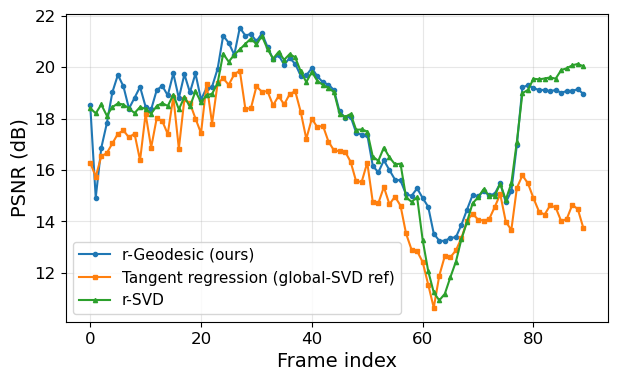

In [37]:
pf = keep['_perframe']
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pf['geodesic'], '-o', ms=3, label='r-Geodesic (ours)')
ax.plot(pf['tangent'],  '-s', ms=3, label='Tangent regression (global-SVD ref)')
ax.plot(pf['r-SVD'],    '-^', ms=3, label='r-SVD')
ax.set_xlabel('Frame index', fontsize=14)
ax.set_ylabel('PSNR (dB)', fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11); ax.grid(alpha=0.3)
fig.savefig('geodesic_vs_tangent_perframe_psnr.png', dpi=300, bbox_inches='tight')
plt.show()

## Visual frame comparison

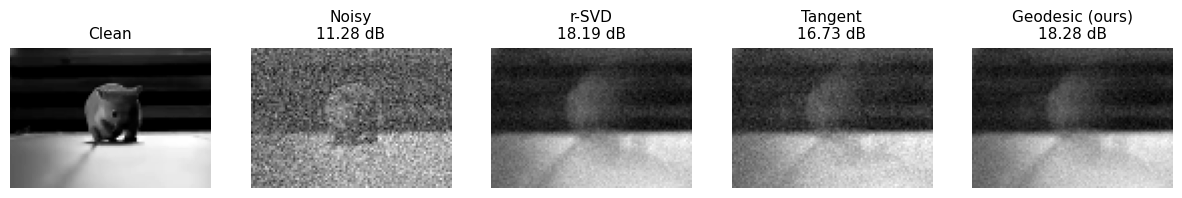

In [38]:
idx = X_clean.shape[1] // 2
titles = ['Clean', 'Noisy', 'r-SVD', 'Tangent', 'Geodesic (ours)']
imgs   = [X_clean, keep['noisy'], keep['r-SVD'], keep['tangent'], keep['geodesic']]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for axx, ttl, im in zip(axes, titles, imgs):
    axx.imshow(np.reshape(im[:, idx], (x, y), order='F'), cmap='gray')
    if ttl == 'Clean':
        axx.set_title(ttl, fontsize=11)
    else:
        p = psnr(normalize_np(im[:, idx]), normalize_np(X_clean[:, idx]))
        axx.set_title(f'{ttl}\n{p:.2f} dB', fontsize=11)
    axx.axis('off')
fig.savefig('geodesic_vs_tangent_frame.png', dpi=300, bbox_inches='tight')
plt.show()

## Noise sweep (the key experiment)

The decoupled two-stage baseline forms noisy local estimates *before* it can average, and its
tangent linearization is only first-order accurate — so the gap to the joint geodesic estimator
should widen as $\sigma_y$ grows.

sigma=0.02  tangent=18.34  geodesic=21.39
sigma=0.05  tangent=18.31  geodesic=20.93
sigma=0.10  tangent=17.96  geodesic=20.20
sigma=0.20  tangent=16.69  geodesic=18.41
sigma=0.30  tangent=15.56  geodesic=16.98
sigma=0.40  tangent=14.65  geodesic=15.72


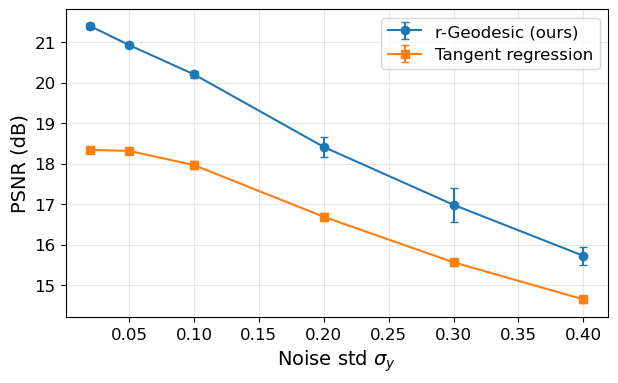

In [40]:
SIGMAS = [0.02, 0.05, 0.10, 0.20, 0.30, 0.40]
SWEEP_TRIALS = 5
sweep = {m: np.zeros((len(SIGMAS), SWEEP_TRIALS)) for m in ['tangent', 'geodesic']}

for si, sg in enumerate(SIGMAS):
    for tr in range(SWEEP_TRIALS):
        Ys = [Xi + np.random.randn(*Xi.shape) * sg for Xi in Xs]

        tang = tangent_regression_baseline(Ys, TS, RANK)

        Xs_init = [Yi.copy() for Yi in Ys]
        geo = init_geodesic(d=d, k=RANK, Xs=Xs_init, init='pca')
        data_init = {"Xs": Xs_init, "ts": TS, "measurements": Ys,
                     "forward": forward, "transpose": transpose, "masks": masks_full}
        geo_est = GeodesicEstimator(rank=RANK).fit(
            geo=geo, data=data_init, callback=noop_cb, niters=NITERS, lambda_fn=LAMBDA)
        geo_recon = np.concatenate(geo_est[1]["Xs"], axis=1)

        sweep['tangent'][si, tr]  = mean_psnr(tang, X_clean)[0]
        sweep['geodesic'][si, tr] = mean_psnr(geo_recon, X_clean)[0]
    print(f'sigma={sg:.2f}  tangent={sweep["tangent"][si].mean():.2f}  '
          f'geodesic={sweep["geodesic"][si].mean():.2f}')

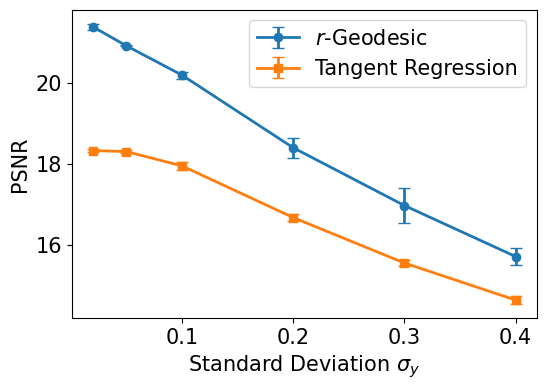

In [45]:
fig, ax = plt.subplots(figsize=(6, 4))
for m, mk, lbl in [('geodesic', '-o', '$r$-Geodesic'),
                   ('tangent',  '-s', 'Tangent Regression')]:
    mu, sd = sweep[m].mean(1), sweep[m].std(1)
    ax.errorbar(SIGMAS, mu, yerr=sd, fmt=mk, capsize=4, label=lbl, linewidth=2,)
ax.set_xlabel(r'Standard Deviation $\sigma_y$', fontsize=15)
ax.set_ylabel('PSNR', fontsize=15)
ax.tick_params(labelsize=15)
ax.legend(fontsize=15)
fig.savefig('geodesic_vs_tangent_noise_sweep.pdf', dpi=500, bbox_inches='tight')
plt.show()